# Instructions

This tutorial performs ECG-FM inference on the PTB-XL dataset downloaded from [Kaggle](https://www.kaggle.com/datasets/khyeh0719/ptb-xl-dataset). It loads the 500 Hz WFDB records, segments each 10 s ECG into non-overlapping 5 s inputs, and produces predictions, embeddings, and saliency maps.

The checkpoint remains the ECG-FM model finetuned on MIMIC-IV-ECG. Therefore, the model output columns are the MIMIC-IV diagnostic labels, not PTB-XL's SCP codes. PTB-XL is used here as an external ECG signal dataset for inference.

ECG-FM was developed in collaboration with the [fairseq_signals](https://github.com/Jwoo5/fairseq-signals) framework, which implements a collection of deep learning methods for ECG analysis.


## Installation

Begin by cloning [fairseq_signals](https://github.com/Jwoo5/fairseq-signals) and refer to the installation section in the top-level README. For example, the following commands are sufficient at the present moment:
```
# Creating `fairseq` environment:
conda create --name fairseq python=3.10.6
source activate fairseq
git clone https://github.com/Jwoo5/fairseq-signals
cd fairseq-signals
python3 -m pip install pip==24.0
python3 -m pip install --user 'transformers<5'
python3 -m pip install --user --no-build-isolation .
```

In [1]:
# You may require the following imports depending on what functionality you run
!pip install huggingface-hub
!pip install pandas
!pip install ecg-transform==0.1.3
!pip install umap-learn
!pip install plotly
!pip install wfdb


Defaulting to user installation because normal site-packages is not writeable


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
import glob
import os
from collections import OrderedDict
from itertools import chain
from typing import Any, Dict, List, Optional, Tuple, Type, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import umap
import wfdb
from huggingface_hub import hf_hub_download
from scipy.ndimage import map_coordinates
from torch.utils.data import Dataset
from torch.utils.data.dataloader import DataLoader

from ecg_transform.inp import ECGInput, ECGInputSchema
from ecg_transform.sample import ECGMetadata, ECGSample
from ecg_transform.t.base import ECGTransform
from ecg_transform.t.common import (
    HandleConstantLeads,
    LinearResample,
    ReorderLeads,
)
from ecg_transform.t.cut import SegmentNonoverlapping
from ecg_transform.t.scale import Standardize
from fairseq_signals.models import build_model_from_checkpoint
from fairseq_signals.models.classification.ecg_transformer_classifier import (
    ECGTransformerClassificationModel,
)


/home/nguyenhuynh/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import os
import glob

root = os.path.dirname(os.getcwd())

## Download checkpoints

Checkpoints are available on [HuggingFace](https://huggingface.co/wanglab/ecg-fm). The finetuned model be downloaded using the following command:

In [4]:
import os
from huggingface_hub import hf_hub_download

hf_hub_download(
    repo_id='wanglab/ecg-fm',
    filename='mimic_iv_ecg_finetuned.pt',
    local_dir=os.path.join(root, 'ckpts'),
)


'/home/hdd/Vlong/ecg-fm/ckpts/mimic_iv_ecg_finetuned.pt'

# Inference

In [5]:
ckpt_path: str = os.path.join(root, 'ckpts/mimic_iv_ecg_finetuned.pt')
assert os.path.isfile(ckpt_path)

ptbxl_candidates = [
    path for path in glob.glob(os.path.join(root, 'data/ptb-xl', '*'))
    if os.path.isfile(os.path.join(path, 'ptbxl_database.csv'))
]
assert len(ptbxl_candidates) == 1, 'Expected one extracted PTB-XL dataset directory.'
ptbxl_root = ptbxl_candidates[0]
ptbxl_records_dir = os.path.join(ptbxl_root, 'records500')
assert os.path.isdir(ptbxl_records_dir)

device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
batch_size: int = 2
num_workers: int = 0

# Set an integer for a quick smoke test; None runs all PTB-XL 500 Hz records.
max_records: int | None = None
extract_saliency: bool = False


In [6]:
from typing import Any, List
import glob


def to_list(obj: Any) -> List[Any]:
    if isinstance(obj, list):
        return obj

    if isinstance(obj, (np.ndarray, set, dict)):
        return list(obj)

    return [obj]

record_headers = sorted(
    glob.glob(os.path.join(ptbxl_records_dir, '**', '*_hr.hea'), recursive=True)
)
file_paths = [os.path.splitext(path)[0] for path in record_headers]
if max_records is not None:
    file_paths = file_paths[:max_records]
assert file_paths, f'No PTB-XL WFDB records found in {ptbxl_records_dir!r}.'
file_paths = to_list(file_paths)
file_paths[:3]


['/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00001_hr',
 '/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00002_hr',
 '/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00003_hr']

## Prepare data

PTB-XL contains 21,837 clinical 12-lead ECGs sampled at 500 Hz or 100 Hz. This notebook uses the 500 Hz records, reads them through WFDB, and resamples/segments them into the 5 s inputs expected by ECG-FM. The record basename is retained as the sample identifier when aggregating segment predictions.


In [7]:
from typing import List
from itertools import chain

import wfdb

import numpy as np

import torch
from torch.utils.data import Dataset
from torch.utils.data.dataloader import DataLoader

from ecg_transform.inp import ECGInput, ECGInputSchema
from ecg_transform.sample import ECGMetadata, ECGSample
from ecg_transform.t.base import ECGTransform
from ecg_transform.t.common import (
    HandleConstantLeads,
    LinearResample,
    ReorderLeads,
)
from ecg_transform.t.scale import Standardize
from ecg_transform.t.cut import SegmentNonoverlapping


class ECGFMDataset(Dataset):
    def __init__(
        self,
        schema,
        transforms,
        file_paths,
    ):
        self.schema = schema
        self.transforms = transforms
        self.file_paths = file_paths

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        signal, fields = wfdb.rdsamp(self.file_paths[idx])
        signal = signal.T.astype(np.float32, copy=False)
        lead_name_map = {'AVR': 'aVR', 'AVL': 'aVL', 'AVF': 'aVF'}
        lead_names = [
            lead_name_map.get(name, name) for name in fields['sig_name']
        ]
        metadata = ECGMetadata(
            sample_rate=int(fields['fs']),
            num_samples=signal.shape[1],
            lead_names=lead_names,
            unit=None,
            input_start=0,
            input_end=signal.shape[1],
        )
        metadata.file = self.file_paths[idx]
        inp = ECGInput(signal, metadata)
        sample = ECGSample(
            inp,
            self.schema,
            self.transforms,
        )
        source = torch.from_numpy(sample.out).float()

        return source, inp


def collate_fn(inps):
    sample_ids = list(
        chain.from_iterable([[inp[1]]*inp[0].shape[0] for inp in inps])
    )
    return torch.concatenate([inp[0] for inp in inps]), sample_ids


def file_paths_to_loader(
    file_paths: List[str],
    schema: ECGInputSchema,
    transforms: List[ECGTransform],
    batch_size=64,
    num_workers=7,
):
    dataset = ECGFMDataset(
        schema,
        transforms,
        file_paths,
    )

    return DataLoader(
        dataset,
        batch_size=batch_size,
        num_workers=num_workers,
        pin_memory=True,
        sampler=None,
        shuffle=False,
        collate_fn=collate_fn,
        drop_last=False,
    )


In [8]:
ECG_FM_LEAD_ORDER = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
SAMPLE_RATE = 500
N_SAMPLES = SAMPLE_RATE*5

# These are the output labels of the MIMIC-IV-finetuned checkpoint.
label_def = pd.read_csv(
    os.path.join(root, 'data/mimic_iv_ecg/labels/label_def.csv'),
    index_col='name',
)
label_names = label_def.index.to_list()
label_names


['Poor data quality',
 'Sinus rhythm',
 'Premature ventricular contraction',
 'Tachycardia',
 'Ventricular tachycardia',
 'Supraventricular tachycardia with aberrancy',
 'Atrial fibrillation',
 'Atrial flutter',
 'Bradycardia',
 'Accessory pathway conduction',
 'Atrioventricular block',
 '1st degree atrioventricular block',
 'Bifascicular block',
 'Right bundle branch block',
 'Left bundle branch block',
 'Infarction',
 'Electronic pacemaker']

In [9]:
AGG_METHODS = {
    'Poor data quality': 'max',
    'Sinus rhythm': 'mean',
    'Premature ventricular contraction': 'max',
    'Tachycardia': 'mean',
    'Ventricular tachycardia': 'max',
    'Supraventricular tachycardia with aberrancy': 'max',
    'Bradycardia': 'mean',
    'Infarction': 'mean',
    'Atrioventricular block': 'mean',
    'Right bundle branch block': 'mean',
    'Left bundle branch block': 'mean',
    'Electronic pacemaker': 'max',
    'Atrial fibrillation': 'mean',
    'Atrial flutter': 'mean',
    'Accessory pathway conduction': 'mean',
    '1st degree atrioventricular block': 'mean',
    'Bifascicular block': 'mean',
}

ECG_FM_SCHEMA = ECGInputSchema(
    sample_rate=SAMPLE_RATE,
    expected_lead_order=ECG_FM_LEAD_ORDER,
    required_num_samples=N_SAMPLES,
)

ECG_FM_TRANSFORMS = [
    ReorderLeads(
        expected_order=ECG_FM_LEAD_ORDER,
        missing_lead_strategy='raise',
    ),
    LinearResample(desired_sample_rate=SAMPLE_RATE),
    HandleConstantLeads(strategy='zero'),
    Standardize(),
    SegmentNonoverlapping(segment_length=N_SAMPLES),
]

loader = file_paths_to_loader(
    file_paths,
    ECG_FM_SCHEMA,
    ECG_FM_TRANSFORMS,
    batch_size=batch_size,
    num_workers=num_workers,
)

## Load model

In [10]:
from typing import Dict, List, Optional, Tuple, Type, Union
from collections import OrderedDict

import numpy as np
import pandas as pd

import torch

from fairseq_signals.models import build_model_from_checkpoint
from fairseq_signals.models.classification.ecg_transformer_classifier import (
    ECGTransformerClassificationModel
)

In [11]:
model: ECGTransformerClassificationModel = build_model_from_checkpoint(
    checkpoint_path=ckpt_path
)

# Forcibly enable the return of attention weights for saliency maps
if extract_saliency:
    model.encoder.encoder.need_weights = extract_saliency
    for layer in model.encoder.encoder.layers:
        layer.need_weights = extract_saliency

model.eval()
model.to(device)

ECGTransformerClassificationModel(
  (encoder): ECGTransformerModel(
    (dropout_input): Dropout(p=0.0, inplace=False)
    (dropout_features): Dropout(p=0.0, inplace=False)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiHeadAttention(
            (dropout): Dropout()
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
          (dropout3): Dropout(p=0.0, inplace=False)
          (self_attn_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (f

## Infer

In [12]:
def encoder_out_to_emb(x, device='cpu'):
    # fairseq_signals/models/classification/ecg_transformer_classifier.py
    return torch.div(x.sum(dim=1), (x != 0).sum(dim=1))

def infer(
    model,
    loader,
    device,
    extract_saliency: bool = False,
):
    inps = []
    sources = []
    logits = []
    embs = []
    saliency = []
    file_names = []
    model.eval()
    with torch.inference_mode():
        for source, inp in loader:
            source = source.to(device, non_blocking=True)
            out = model(source=source)
            inps.extend(inp)
            # Move every batch off the GPU before loading the next one.
            sources.append(source.cpu())
            logits.append(out['out'].cpu())
            embs.append(encoder_out_to_emb(out['encoder_out']).cpu())
            if extract_saliency:
                if out['saliency'] is None:
                    raise RuntimeError(
                        'Saliency was requested, but the model did not return '
                        'attention weights. Re-run the model-loading cell with '
                        'extract_saliency=True.'
                    )
                saliency.append(out['saliency'].cpu())
            file_names.extend([i.meta.file for i in inp])
            del source, out

    # Handle predictions
    pred = torch.sigmoid(torch.concatenate(logits)).detach().cpu().numpy()
    pred = pd.DataFrame(pred, columns=label_names, index=file_names)

    results = {
        'inps': inps,
        'sources': torch.concatenate(sources).detach().cpu().numpy(),
        'embs': torch.concatenate(embs).detach().cpu().numpy(),
        'pred': pred,
    }

    # Handle saliency
    if extract_saliency:
        saliency = torch.concatenate(saliency).detach()
        attn = saliency[:, -1] # Consider only the last attention layer
        results['attn_max'] = attn.max(axis=2).values.squeeze().cpu().detach().numpy()

    return results

In [13]:
results = infer(
    model,
    loader,
    device,
    extract_saliency=extract_saliency,
)

In [14]:
pred = results['pred']
print(f"Number of 5 s segment predictions: {len(pred)}.")
pred

Number of 5 s segment predictions: 43674.


,Poor data quality,Sinus rhythm,Premature ventricular contraction,Tachycardia,Ventricular tachycardia,Supraventricular tachycardia with aberrancy,Atrial fibrillation,Atrial flutter,Bradycardia,Accessory pathway conduction,Atrioventricular block,1st degree atrioventricular block,Bifascicular block,Right bundle branch block,Left bundle branch block,Infarction,Electronic pacemaker
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00001_hr,0.275102,0.941203,0.112420,0.092849,9.583430e-02,0.021918,0.126379,0.615021,0.037126,0.232463,0.031607,0.010840,0.003093,0.009536,0.054656,0.018432,0.130007
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00001_hr,0.670510,0.994439,0.122094,0.021086,1.074887e-02,0.002844,0.019495,0.003777,0.079636,0.023540,0.002426,0.001589,0.000704,0.003578,0.028265,0.041330,0.268574
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00002_hr,0.019339,0.939127,0.053680,0.005154,4.680501e-08,0.000065,0.003980,0.000070,0.979161,0.006572,0.002897,0.001565,0.000041,0.000394,0.001320,0.094714,0.015611
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00002_hr,0.045382,0.987803,0.091307,0.002902,1.208846e-09,0.000012,0.001394,0.000010,0.968435,0.002371,0.000826,0.000629,0.000008,0.000324,0.000336,0.085603,0.007755
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00003_hr,0.168075,0.964412,0.066202,0.021784,5.035399e-06,0.000594,0.017452,0.001755,0.108862,0.031700,0.002154,0.001380,0.000031,0.001312,0.008108,0.032925,0.234568
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21835_hr,0.036357,0.997081,0.006569,0.038940,3.877612e-05,0.000247,0.015428,0.000449,0.564512,0.016981,0.001770,0.001014,0.000002,0.003941,0.055211,0.024924,0.122160
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21836_hr,0.213626,0.976900,0.198852,0.029894,3.859059e-03,0.001775,0.022302,0.001986,0.025595,0.033780,0.035053,0.060651,0.000616,0.002161,0.041696,0.069099,0.600571
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21836_hr,0.205027,0.978683,0.794689,0.065228,1.121431e-02,0.002021,0.028873,0.018176,0.045373,0.028591,0.098489,0.112545,0.001011,0.003424,0.009270,0.043585,0.274427
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21837_hr,0.222362,0.776584,0.038268,0.265788,6.689902e-04,0.034457,0.343307,0.285827,0.666373,0.299476,0.031570,0.019308,0.000518,0.015921,0.013200,0.028770,0.089417


# Result handling

## Prediction aggregation

In [15]:
pred_agg = pred.groupby(pred.index).agg(AGG_METHODS).astype(float)
print(f"Number of sample-aggregated predictions: {len(pred_agg)}.")
pred_agg

Number of sample-aggregated predictions: 21837.


,Poor data quality,Sinus rhythm,Premature ventricular contraction,Tachycardia,Ventricular tachycardia,Supraventricular tachycardia with aberrancy,Bradycardia,Infarction,Atrioventricular block,Right bundle branch block,Left bundle branch block,Electronic pacemaker,Atrial fibrillation,Atrial flutter,Accessory pathway conduction,1st degree atrioventricular block,Bifascicular block
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00001_hr,0.670510,0.967821,0.122094,0.056967,9.583430e-02,0.021918,0.058381,0.029881,0.017016,0.006557,0.041461,0.268574,0.072937,0.309399,0.128001,0.006215,0.001898
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00002_hr,0.045382,0.963465,0.091307,0.004028,4.680501e-08,0.000065,0.973798,0.090159,0.001861,0.000359,0.000828,0.015611,0.002687,0.000040,0.004471,0.001097,0.000025
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00003_hr,0.286709,0.969558,0.154583,0.020354,5.035399e-06,0.001027,0.097666,0.036152,0.001864,0.001358,0.025939,0.234568,0.015119,0.001452,0.031362,0.001200,0.000040
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00004_hr,0.067857,0.925225,0.076821,0.011568,1.470133e-11,0.000013,0.032475,0.015105,0.001388,0.000302,0.001020,0.000992,0.001863,0.000022,0.002717,0.000745,0.000018
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/00000/00005_hr,0.012566,0.989729,0.011075,0.007491,7.228488e-10,0.000033,0.069934,0.008927,0.001018,0.000115,0.000492,0.023618,0.002874,0.000197,0.005386,0.000913,0.000004
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21833_hr,0.097344,0.914234,0.988163,0.992864,8.677790e-05,0.371535,0.007119,0.071585,0.004177,0.023922,0.000551,0.036707,0.068439,0.003535,0.017236,0.001552,0.000908
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21834_hr,0.797285,0.996766,0.472557,0.043044,4.243128e-01,0.003855,0.072997,0.800567,0.003211,0.005724,0.091600,0.105858,0.029629,0.000314,0.010379,0.002610,0.000343
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21835_hr,0.036357,0.994257,0.018399,0.036567,3.877612e-05,0.000247,0.669226,0.025045,0.001470,0.002304,0.040837,0.187604,0.018336,0.000262,0.014120,0.000981,0.000001
/home/hdd/Vlong/ecg-fm/data/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/records500/21000/21836_hr,0.213626,0.977792,0.794689,0.047561,1.121431e-02,0.002021,0.035484,0.056342,0.066771,0.002792,0.025483,0.600571,0.025587,0.010081,0.031186,0.086598,0.000814


## Visualizing embeddings

/home/nguyenhuynh/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/nguyenhuynh/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:373: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)
/home/nguyenhuynh/.local/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


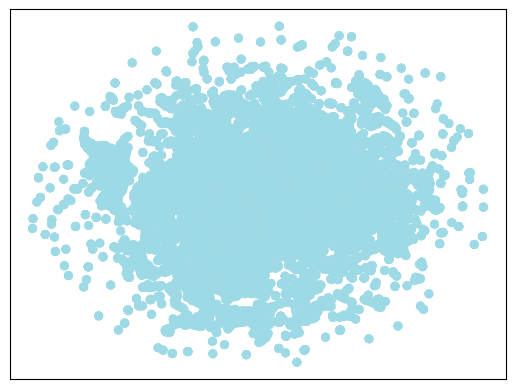

In [16]:
import matplotlib.pyplot as plt
import umap

reducer = umap.UMAP(n_neighbors=3, min_dist=0.1, n_components=2, random_state=42)
embs_2d = reducer.fit_transform(results['embs'])

# Generate a color map
sample_identifier = pred.index.to_series()
unique_values = sample_identifier.unique()
colors = plt.colormaps.get_cmap('tab20')  # Use a colormap with enough distinct colors
color_map = {val: colors(i) for i, val in enumerate(unique_values)}
colored_items = sample_identifier.map(color_map)

# Plot the 2D UMAP visualization
plt.scatter(
    embs_2d[:, 0],
    embs_2d[:, 1],
    s=30,
    alpha=0.9,
    color=colored_items.values,
    rasterized=True,
)

# Remove axis labels and grid
plt.xticks([])
plt.yticks([])
plt.grid(False)

More fitting when visualizing many embeddings:
```
import matplotlib.pyplot as plt
import umap
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42) # Better when there are more embeddings

# Plot the 2D UMAP visualization
plt.scatter(
    embs_2d[:, 0],
    embs_2d[:, 1],
    s=1,
    alpha=0.9,
    rasterized=True,
)

# Remove axis labels and grid
plt.xticks([])
plt.yticks([])
plt.grid(False)
```

## Saliency maps

In [17]:
from typing import Tuple

import numpy as np

from scipy.ndimage import map_coordinates

import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [18]:
sample_idx = 0

saliency_lead = 'II'
lead_ind = ECG_FM_LEAD_ORDER.index(saliency_lead)

In [20]:
if 'attn_max' not in results:
    raise RuntimeError(
        "Saliency data is not available in results. Set extract_saliency=True "
        "before loading the model and rerun the model-loading and inference cells. "
        "For GPU memory, use max_records=1 and batch_size=1."
    )

signal = results['sources'][sample_idx, lead_ind]
attn_max = results['attn_max'][sample_idx]

RuntimeError: Saliency data is not available in results. Set extract_saliency=True before loading the model and rerun the model-loading and inference cells. For GPU memory, use max_records=1 and batch_size=1.

In [ ]:
def blend_colors_hex(start_color: str, end_color: str, activations: np.ndarray) -> np.ndarray:
    """
    Blends between two colors based on an array of blend factors.

    Parameters
    ----------
    start_color : str
        Hexadecimal color code for the start color.
    end_color : str
        Hexadecimal color code for the end color.
    activations : np.ndarray
        An array of blend factors where 0 corresponds to the start color and 1 to the end color.

    Returns
    -------
    np.ndarray
        An array of hexadecimal color codes resulting from the blends.

    Raises
    ------
    ValueError
        If any of the input blend factors are not within the range [0, 1].
    """
    if np.any((activations < 0) | (activations > 1)):
        raise ValueError("All blend factors must be between 0 and 1.")

    # Convert hexadecimal to RGB
    def hex_to_rgb(hex_color: str) -> Tuple[int]:
        return tuple(int(hex_color[i: i+2], 16) for i in (1, 3, 5))

    # Get RGB tuples
    start_rgb = np.array(hex_to_rgb(start_color))
    end_rgb = np.array(hex_to_rgb(end_color))

    # Blend RGB values
    blended_rgb = np.outer(1 - activations, start_rgb) + np.outer(activations, end_rgb)

    # Convert blended RGB back to hex codes
    return blended_rgb / 255

def colored_line_segments(data: np.ndarray, colors: np.ndarray, ax=None, **kwargs):
    """
    Plots line segments based on the provided data points, with each segment
    colored according to the corresponding color specification in `colors`.

    Parameters
    ----------
    data : np.ndarray
        Array of y-values for the line segments.
    colors : np.ndarray
        Array of colors, each color applied to the corresponding line segment
        between points i and i+1.

    Raises
    ------
    ValueError
        If the `colors` array does not have exactly one less element than the `data` array,
        as each segment needs a unique color.

    Returns
    -------
    None
    """
    if len(colors) != len(data) - 1:
        raise ValueError("Colors array must have one fewer elements than data array.")

    if ax is None:
        for i in range(len(data) - 1):
            plt.plot([i, i + 1], [data[i], data[i + 1]], color=colors[i], **kwargs)
    else:
        for i in range(len(data) - 1):
            ax.plot([i, i + 1], [data[i], data[i + 1]], color=colors[i], **kwargs)

def prep_saliency_values(attn_max, target_sample_length):
    # Resample to original sample size
    new_dims = [
        np.linspace(0, original_length-1, new_length) \
        for original_length, new_length in \
        zip(attn_max.shape, (target_sample_length - 1,))
    ]
    coords = np.meshgrid(*new_dims, indexing='ij')
    attn_max = map_coordinates(attn_max, coords)

    # Min-max normalization
    attn_max = attn_max - attn_max.min()
    attn_max = attn_max/attn_max.max()

    return attn_max

saliency_prepped = prep_saliency_values(
    attn_max.ravel(),
    attn_max.shape[0] * signal.shape[-1],
)
saliency_colors = blend_colors_hex('#0047AB', '#DC143C', saliency_prepped)
saliency_colors = (saliency_colors*255).astype(int)

# Define a custom colorscale from blue to red
colorscale = [[0, 'blue'], [1, 'red']]  # Simple gradient from blue to red

time = np.arange(2500)

# Create the figure
fig = go.Figure()
y_values = signal[:-1]
for i in range(len(y_values) - 1):
    fig.add_trace(
        go.Scatter(
            x=[time[i], time[i + 1]],
            y=[y_values[i], y_values[i + 1]],
            mode='lines',
            line=dict(color='rgb({},{},{})'.format(*saliency_colors[i]), width=2),
            showlegend=False  # Avoid cluttering the legend
        )
    )
fig['layout']['yaxis'].update(autorange = True)
fig['layout']['xaxis'].update(autorange = True)

fig.show()